# Which detector should teach the adaptive loop?

**Question.** The adaptive loop learns each room's code from a teacher's labels. The teacher only sees the full frames the tag sends: grayscale 160×120. Which COCO detector, at which input scale, gives the most correct labels on those frames? The loop needs both kinds of label: person and empty.

**Setup.**
* Teachers are torchvision COCO detectors, written `model@min_size` (the detector's internal resize of the 160×120 frame). The current teacher is `frcnn_mnv3_320@320`. Per frame the score is the highest *person* confidence (0 if there is none).
* Frames: every 8th frame of the five annotated sequences, corrupted frames excluded. Scores come from `experiments/teacher_eval.py --stride 8` (`results/teachers/<teacher>_s8/`); this notebook only analyses them.
* Rooms: **A** = `training`, `test1`, `test3` (the default layout) and **A2** = `training_seats`, `test2` (seats moved in; people mostly seated and half hidden). The loop has to work in each room on its own, so every result is per room.
* Labels: the annotations miss people (about 8% of empty-labelled `training` frames show one). So besides the **annotation** labels there are **corrected** labels: a frame also counts as person if the full-resolution colour detector (`results/coco_detectors/frcnn_mnv3_320_rgb_s2.npz`) scores it 0.9 or higher. The corrected labels are the reference below unless stated otherwise.

Two measures:
1. **AUC**, threshold-free: how well a teacher ranks person frames above empty ones.
2. **Clean-label coverage**: the share of frames a teacher can label with at most 1% wrong labels, split into person and empty labels. The cutoffs are chosen *from the labels*, which a deployed loop cannot do, so this is only for ranking teachers. It does show whether a teacher can give clean **empty** labels at all, and AUC hides that.

## 1. Load scores and labels

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..').resolve()))
from semwisp import piropo
from semwisp.frames import load_frames

ROOMS = {'A': ['training', 'test1', 'test3'], 'A2': ['training_seats', 'test2']}
STRIDE = 8
TEACHER_DIR = piropo.REPO / 'results' / 'teachers'
FULLRES = np.load(piropo.REPO / 'results' / 'coco_detectors' / 'frcnn_mnv3_320_rgb_s2.npz')
CURRENT = 'frcnn_mnv3_320@320'
PERSON_C, EMPTY_C = '#2a78d6', '#eb6834'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']   # fixed categorical order

frames = load_frames(piropo.ANNOTATED)
teachers = sorted(p.name[:-len(f'_s{STRIDE}')] for p in TEACHER_DIR.glob(f'*_s{STRIDE}')
                  if all((p / f'{n}.npz').exists() for n in piropo.ANNOTATED))
skipped = sorted(p.name for p in TEACHER_DIR.glob(f'*_s{STRIDE}') if p.name[:-len(f'_s{STRIDE}')] not in teachers)
print('teachers:', teachers)
print('incomplete, left out:', skipped)

def fullres_score(name, idx):
    lookup = dict(zip(FULLRES[f'idx_{name}'], FULLRES[f'score_{name}']))
    return np.array([lookup[i] for i in idx])   # stride 2 covers every stride-8 frame

rows = []
for t in teachers:
    for room, names in ROOMS.items():
        for n in names:
            d = np.load(TEACHER_DIR / f'{t}_s{STRIDE}' / f'{n}.npz')
            idx = d['idx']
            keep = ~frames[n]['bad'][idx]
            ann = frames[n]['label'][idx].astype(bool)
            rows.append(pd.DataFrame(dict(teacher=t, room=room, seq=n, idx=idx, score=d['score'],
                                          ann=ann, person=ann | (fullres_score(n, idx) >= 0.9)))[keep])
S = pd.concat(rows, ignore_index=True)
counts = S[S.teacher == CURRENT].groupby('room').agg(frames=('score', 'size'), annotated_person=('ann', 'sum'),
                                                    corrected_person=('person', 'sum'))
counts['corrected_empty'] = counts.frames - counts.corrected_person
counts

teachers: ['fcos_r50@480', 'frcnn_mnv3@800', 'frcnn_mnv3_320@320', 'frcnn_mnv3_320@640', 'kprcnn_r50@480', 'retina_r50v2@480']
incomplete, left out: ['frcnn_r50v2@480_s8']


,frames,annotated_person,corrected_person,corrected_empty
room,,,,
A,575,425,435,140
A2,280,157,158,122


## 2. AUC per room

AUC against the annotation labels and against the corrected labels. The gap between the two is the annotations' missed people: a teacher that scores them high is penalised by the annotation labels.

In [2]:
auc = (S.groupby(['teacher', 'room'])
         .apply(lambda g: pd.Series({'annotation': piropo.auc(g.score, g.ann), 'corrected': piropo.auc(g.score, g.person)}),
                include_groups=False)
         .unstack('room').swaplevel(axis=1).sort_index(axis=1))
auc[('both rooms', 'corrected')] = S.groupby('teacher').apply(lambda g: piropo.auc(g.score, g.person), include_groups=False)
auc = auc.sort_values(('both rooms', 'corrected'), ascending=False)
auc.style.format('{:.3f}').background_gradient(cmap='RdYlGn', vmin=0.8, vmax=1.0)

## 3. The loop's fixed cutoffs

`AdaptiveServer` labels a frame person at score ≥ 0.6 and empty at ≤ 0.3, and asks for nothing in between. Below: the share of frames each teacher labels at those cutoffs and how many of those labels are wrong, against both label sets. The last three columns use a strict empty cutoff, ≤ 0.05.

Score scales differ between models (FCOS puts most frames between 0.2 and 0.8), so these cutoffs are not fair to the other teachers. They are what the loop would do if a teacher were swapped in unchanged.

In [3]:
def at_cutoffs(g, pos, neg):
    P, E = g.score >= pos, g.score <= neg
    return pd.Series({
        'person labels': P.mean(), 'person wrong (ann.)': (~g.ann[P]).mean(), 'person wrong (corr.)': (~g.person[P]).mean(),
        'empty labels': E.mean(), 'empty wrong (ann.)': g.ann[E].mean(), 'empty wrong (corr.)': g.person[E].mean()})

fixed = S.groupby(['teacher', 'room']).apply(at_cutoffs, pos=0.6, neg=0.3, include_groups=False)
strict = S.groupby(['teacher', 'room']).apply(at_cutoffs, pos=0.6, neg=0.05, include_groups=False).iloc[:, 3:]
strict.columns = [c.replace('empty', 'empty ≤0.05') for c in strict.columns]
tab = pd.concat([fixed, strict], axis=1)
tab.style.format('{:.0%}', na_rep='–').background_gradient(cmap='Reds', vmin=0, vmax=0.4,
                                                            subset=[c for c in tab.columns if 'wrong' in c])

## 4. Clean-label coverage

For each teacher and room, the most permissive cutoffs that keep each kind of label at most 1% wrong (corrected labels):
* person cutoff: the lowest score `c` such that every threshold from `c` upward has ≤ 1% empty frames among the frames at or above it;
* empty cutoff: the highest score `c` such that every threshold from `c` downward has ≤ 1% person frames among the frames at or below it.

Requiring every threshold beyond the cutoff to pass (not just the cutoff itself) keeps the cutoffs monotone, so a slightly stricter cutoff is never worse. If the two cutoffs still meet or cross, frames with scores in the overlap are left unlabelled rather than given both labels (`overlap` column). *Empty recall* is the share of the room's truly empty frames that get an empty label; the loop has nothing to learn "empty" from without them.

In [4]:
ERR = 0.01

def clean_cutoffs(score, person, err=ERR):
    """(person cutoff, empty cutoff); inf / -inf if no cutoff keeps the error at or below err."""
    u = np.unique(score)
    s_sorted = np.sort(score)
    p_sorted = person[np.argsort(score, kind='stable')]
    cum_p = np.concatenate([[0], np.cumsum(p_sorted)])
    lo, hi = np.searchsorted(s_sorted, u, 'left'), np.searchsorted(s_sorted, u, 'right')
    n_above, empty_above = len(score) - lo, (len(score) - lo) - (cum_p[-1] - cum_p[lo])   # frames with score >= u
    n_below, person_below = hi, cum_p[hi]                                                # frames with score <= u
    bad = np.flatnonzero(empty_above > err * n_above)
    i = bad[-1] + 1 if len(bad) else 0
    pos = u[i] if i < len(u) else np.inf
    bad = np.flatnonzero(person_below > err * n_below)
    i = bad[0] - 1 if len(bad) else len(u) - 1
    neg = u[i] if i >= 0 else -np.inf
    return pos, neg

def coverage(g):
    s, y = g.score.to_numpy(), g.person.to_numpy()
    pos, neg = clean_cutoffs(s, y)
    overlap = (s >= pos) & (s <= neg)
    P, E = (s >= pos) & ~overlap, (s <= neg) & ~overlap
    return pd.Series({'person cutoff': pos, 'empty cutoff': neg, 'overlap': overlap.sum(),
                      'person labels': P.mean(), 'empty labels': E.mean(), 'coverage': (P | E).mean(),
                      'empty labels (n)': E.sum(), 'empty frames (n)': (~y).sum(), 'empty recall': E.sum() / (~y).sum(),
                      'wrong': np.r_[~y[P], y[E]].mean() if (P | E).any() else np.nan})

cov = S.groupby(['teacher', 'room']).apply(coverage, include_groups=False)
cov = cov.astype({'overlap': int, 'empty labels (n)': int, 'empty frames (n)': int})
(cov.style.format({'person cutoff': '{:.3f}', 'empty cutoff': '{:.3f}', 'person labels': '{:.0%}', 'empty labels': '{:.0%}',
                   'coverage': '{:.0%}', 'empty recall': '{:.0%}', 'wrong': '{:.1%}'})
    .background_gradient(cmap='RdYlGn', vmin=0, vmax=1, subset=['coverage', 'empty recall']))

Summary per teacher: AUC and coverage in each room, and empty recall (the scarce label) at the 1% bar and at a looser 5% bar. The 1% bar is strict: a handful of person frames scored at the teacher's floor (often 0, no detection at all) rules out every empty cutoff.

In [5]:
summary = pd.concat({
    'AUC': auc.xs('corrected', axis=1, level=1)[list(ROOMS)],
    'coverage': cov.coverage.unstack('room'),
    'empty recall': cov['empty recall'].unstack('room'),
    'empty recall, ≤5% wrong': S.groupby(['teacher', 'room']).apply(
        lambda g: ((g.score <= clean_cutoffs(g.score.to_numpy(), g.person.to_numpy(), 0.05)[1]) & ~g.person).sum() / (~g.person).sum(),
        include_groups=False).unstack('room'),
}, axis=1).sort_values(('AUC', 'A2'), ascending=False)
summary.style.format('{:.3f}', subset=['AUC']).format('{:.0%}', subset=['coverage', 'empty recall', 'empty recall, ≤5% wrong'])

## 5. Score distributions

Each teacher's scores on person and empty frames (corrected labels, log counts), per room, with the clean-label cutoffs from section 4 (black solid: person cutoff, black dashed: empty cutoff) and the loop's fixed 0.6 / 0.3 (gray dotted). A good teacher for the loop leaves a band of empty frames below every person frame.

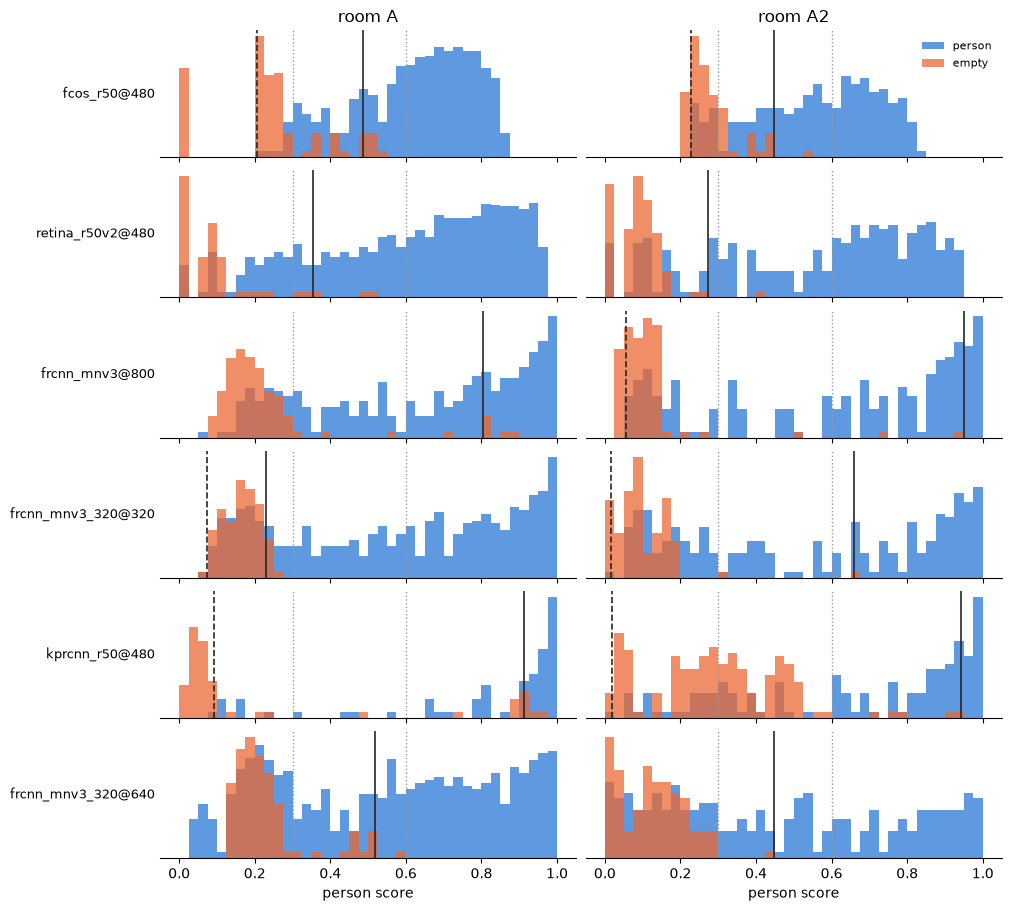

In [6]:
order = summary.index.tolist()
fig, axes = plt.subplots(len(order), 2, figsize=(10, 1.5 * len(order)), sharex=True, constrained_layout=True)
bins = np.linspace(0, 1, 41)
for i, t in enumerate(order):
    for j, room in enumerate(ROOMS):
        ax, g = axes[i, j], S[(S.teacher == t) & (S.room == room)]
        ax.hist(g.score[g.person], bins, color=PERSON_C, alpha=0.75, label='person')
        ax.hist(g.score[~g.person], bins, color=EMPTY_C, alpha=0.75, label='empty')
        c = cov.loc[t, room]
        for x in (0.6, 0.3):
            ax.axvline(x, color='0.6', ls=':', lw=1)
        if np.isfinite(c['person cutoff']): ax.axvline(c['person cutoff'], color='0.15', lw=1.2)
        if np.isfinite(c['empty cutoff']): ax.axvline(c['empty cutoff'], color='0.15', lw=1.2, ls='--')
        ax.set_yscale('log'); ax.set_yticks([], minor=True); ax.set_yticks([])
        for sp in ['top', 'right', 'left']: ax.spines[sp].set_visible(False)
        if j == 0: ax.set_ylabel(t, rotation=0, ha='right', va='center', fontsize=9)
        if i == 0: ax.set_title(f'room {room}')
axes[0, 1].legend(frameon=False, fontsize=8)
axes[-1, 0].set_xlabel('person score'); axes[-1, 1].set_xlabel('person score')
plt.show()

## 6. Empty labels: how many, at what error

Empty labels are the scarce ones. For each teacher, sweep the empty cutoff and plot the share of the room's empty frames labelled empty against the share of those labels that are wrong (gray dotted: 1%). This is the curve step 3 has to pick a point on without labels.

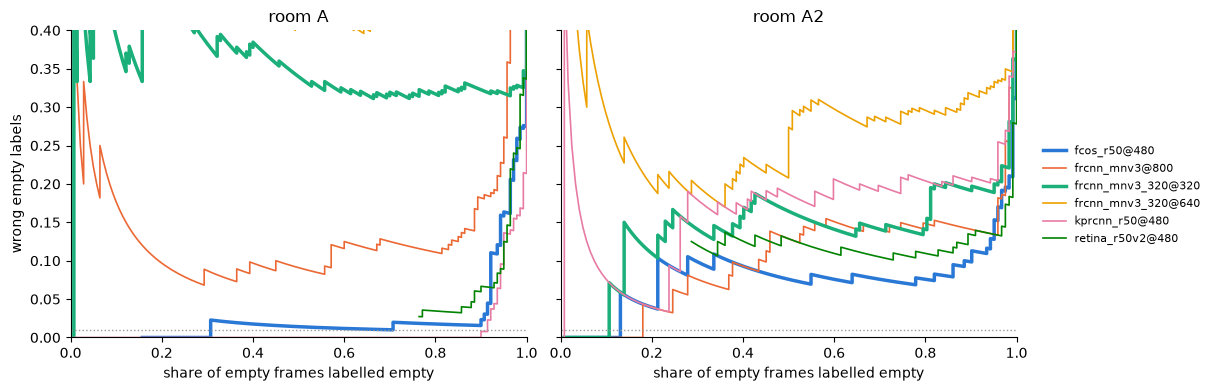

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, layout='constrained')
for j, room in enumerate(ROOMS):
    ax = axes[j]
    for k, t in enumerate(teachers):
        g = S[(S.teacher == t) & (S.room == room)]
        s, y = g.score.to_numpy(), g.person.to_numpy()
        cuts = np.unique(s)
        rec = np.array([((s <= c) & ~y).sum() for c in cuts]) / (~y).sum()
        err = np.array([y[s <= c].mean() for c in cuts])
        ax.plot(rec, err, color=SERIES[k], lw=2.5 if t in (CURRENT, 'fcos_r50@480') else 1.2, label=t)
    ax.axhline(ERR, color='0.6', lw=1, ls=':')
    ax.set_xlim(0, 1); ax.set_ylim(0, 0.4); ax.set_title(f'room {room}')
    ax.set_xlabel('share of empty frames labelled empty')
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
axes[0].set_ylabel('wrong empty labels')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside right center', frameon=False, fontsize=8)
plt.show()

## Findings

* **Ranking (AUC, corrected labels).** FCOS at 480 is the only candidate better than the current teacher in both rooms: A 0.992 vs 0.917, A2 0.959 vs 0.922. Keypoint R-CNN is best in A (0.996) and second-worst in A2 (0.906). Upscaling the current model's input (`frcnn_mnv3_320@640`) hurts in both rooms. Against the raw annotations every teacher loses about 0.03 AUC in room A and little in A2: the missed people are in room A.
* **Empty labels are the bottleneck, and AUC hides it.** At stride 8 room A has 140 empty frames out of 575 and A2 has 122 out of 280. The current teacher can label 1 of room A's 140 empty frames at ≤ 1% wrong, and 13 of 122 in A2. Its 65% coverage in room A is almost all person labels. At the loop's 0.3 cutoff, 36% (A) and 28% (A2) of its empty labels are wrong.
* **FCOS with the loop's cutoffs unchanged** (≥ 0.6 / ≤ 0.3): no wrong person labels against the corrected labels, and 4% (A) / 11% (A2) wrong empty labels. Its empty frames sit in a tight cluster at 0.2–0.3 (plus a group at 0 in room A), and its clean empty cutoff is about 0.21 in A and 0.23 in A2. A label-free rule that finds the lower mode of the score distribution looks feasible.
* **Room A2's empty frames are hard for every teacher.** No teacher labels more than 18% of them at ≤ 1% wrong, or more than 25% at ≤ 5% wrong. FCOS's best is about 4% wrong at 13–20% of A2's empty frames (section 6). Seated, half-hidden people score in the same range as the empty room.
* **Monotone cutoffs change the earlier coverage numbers.** The first (scratch) comparison took the lowest passing cutoff even when stricter cutoffs failed. With monotone cutoffs, FCOS drops from 88% to 77% coverage in room A, the current teacher from 45% to 36% in A2, and `frcnn_mnv3@800` from 44% to 25% in A2. The other numbers are unchanged. The person and empty cutoffs never overlap here.
* **Score floor (found after this analysis).** `teacher_eval.py` asked every model for a 0.01 score floor through `box_score_thresh`, which FCOS and RetinaNet ignore: their floors were 0.2 and 0.05, and scores below them were stored as 0 (fixed 2026-11-13). Scores above the floor are unaffected. FCOS has 22 zeros at stride 8, so its numbers barely change. RetinaNet has 150, all tied at 0, which may be why it shows no clean empty labels: rescore it before relying on its empty-label numbers.
* **Caveats.** The cutoffs in sections 4–6 are fitted to the labels, so they rank teachers and do not describe a deployed loop. The corrected labels come from the full-resolution colour version of the current teacher's own architecture. They only add person frames, but they can't flag a person that this model misses at full resolution. There are few empty frames at stride 8. FCOS's stride-2 scores (`results/teachers/fcos_r50@480_s2/`, 4× the frames) confirm room A (AUC 0.987, 31% empty recall at ≤ 1% wrong, 4.4% wrong empty labels at 0.3) but not A2's empty recall: at stride 2 FCOS labels only **2%** of A2's 487 empty frames at ≤ 1% wrong (13% at stride 8, small-sample luck). Its A2 AUC (0.958) and wrong empty labels at 0.3 (10.6%) hold.